# 01 · Simulation setup and a first second moon

This notebook covers Phase 1 of the project:

1. Real initial conditions from NASA JPL Horizons
2. Validation of the simulation against the JPL lunar ephemeris
3. A hypothetical second moon
4. Its evolution over 10 years
5. A numerical accuracy check

Reusable code lives in `src/`; this notebook calls it and presents the results. Runtime is about
one minute. Terms are defined in [`docs/glossary.md`](../docs/glossary.md), and all figures are
described in [`docs/figures.md`](../docs/figures.md).

![Both moons orbiting Earth for 60 days](../figures/two_moons.gif)

*60 days viewed from above the ecliptic, centered on Earth. The inner second moon completes about
four orbits per lunar orbit, as expected from Kepler's third law.*

## Setup

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))  # so the notebook can find our code

import numpy as np

from horizons import ROOT, load_state
from simulate import DAY_S, load_config, run

## 1. Initial conditions

The system is integrated as an N-body problem: each body's motion follows from the gravity of all
the others, advanced numerically in small time steps with [REBOUND](https://rebound.readthedocs.io/).
The integration requires only the masses and one state vector (position and velocity) per body.

State vectors for the Sun, Earth and Moon are taken from JPL Horizons at 2026-01-01 00:00 TDB
(DE440 ephemeris, barycentric ecliptic frame) and stored in `configs/initial_state.json`, so every
run starts from identical values. The cell below converts the Moon's state vector into orbital
elements.

In [2]:
from check_initial_state import moon_orbit

state = load_state()
print("Date:", state["epoch_tdb"], "TDB")
for name, value in moon_orbit(state).items():
    print(f"{name:20s} {value:,.4f}")

Date: 2026-01-01 00:00:00 TDB
distance_km          361,026.0109
semi_major_axis_km   384,468.8281
eccentricity         0.0629
inclination_deg      5.0596
period_days          27.2919


At the epoch, the Moon is 361,026 km from Earth, near perigee, while its semi-major axis is
about 384,000 km. The eccentricity (0.063), the inclination to the ecliptic (5.06°) and the
sidereal period (27.29 days) agree with standard values. These are osculating elements: solar
perturbations change them continuously.

## 2. Validation against JPL

Before introducing a hypothetical body, the setup is tested on the real system: the Sun, Earth and
Moon are integrated for one year and the Moon's position is compared with the JPL ephemeris. The
integrator is IAS15, which adapts its step size and keeps errors near machine precision.

A second run without the Sun serves as a reference for how much solar perturbations contribute.
The residual difference reflects omitted physics (other planets, Earth's oblateness, tides,
general relativity); the individual contributions are not separated here.

With the Sun:    largest error 10.3 km
Without the Sun: largest error 55,535 km


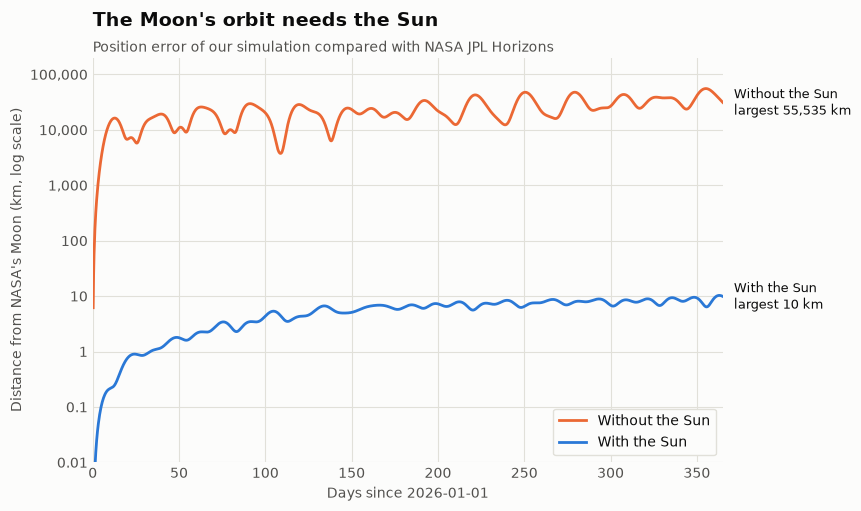

In [3]:
from plot_real_system import plot_error
from validate_real_system import compare

comparison = compare()
print(f"With the Sun:    largest error {comparison['error_km'].max():,.1f} km")
print(f"Without the Sun: largest error {comparison['error_without_sun_km'].max():,.0f} km")
plot_error(comparison);

**Result.** With the Sun, the maximum error over one year is 10.3 km, about 0.003% of the
Earth-Moon distance. Without it, the error reaches 55,535 km within the same year (note the
logarithmic axis). The slow growth of the blue curve is consistent with small unmodeled effects
accumulating over time.

This comparison guards against errors in units, epochs or missing bodies, any of which would show
up as a much larger discrepancy.

## 3. A hypothetical second moon

The second moon is specified by its mass and orbital elements relative to Earth, which are
converted to a state vector:

| Parameter | Meaning | Value |
|---|---|---|
| `mass_lunar` | Mass in lunar masses | 0.1 |
| `distance_lunar` | Semi-major axis in lunar distances (384,400 km) | 0.4 |
| `eccentricity` | Orbital eccentricity | 0 |
| `inclination_deg` | Inclination to the ecliptic; above 90° is retrograde | 0 |
| `node_deg`, `periapsis_deg` | Longitude of the ascending node, argument of periapsis | 0 |
| `true_anomaly_deg` | Starting position along the orbit | 0 |

This first case is a low-mass, circular, planar orbit well inside the Moon's. The body is assigned
the Moon's density, which sets its radius for collision detection.

The integration runs for 10 years and stops at the first **collision** (detected along every
integration step) or **ejection** (more than 4.5 million km from Earth and unbound).

In [4]:
config = load_config(ROOT / "configs" / "single_run.json")
for name, value in config["second_moon"].items():
    print(f"{name:18s} {value}")

result = run(state, config)
print(f"\nOutcome after {result.end_time_s / DAY_S:,.0f} days: {result.outcome}")

mass_lunar         0.1
distance_lunar     0.4
eccentricity       0.0
inclination_deg    0.0
node_deg           0.0
periapsis_deg      0.0
true_anomaly_deg   0.0



Outcome after 3,650 days: survived


## 4. Evolution over 10 years

Earth distance of both moons; each oscillation is one orbit.

Moon, first year: spread 46,115 km
Moon, last year: spread 44,541 km
Second moon, first year: spread 5,847 km
Second moon, last year: spread 14,726 km


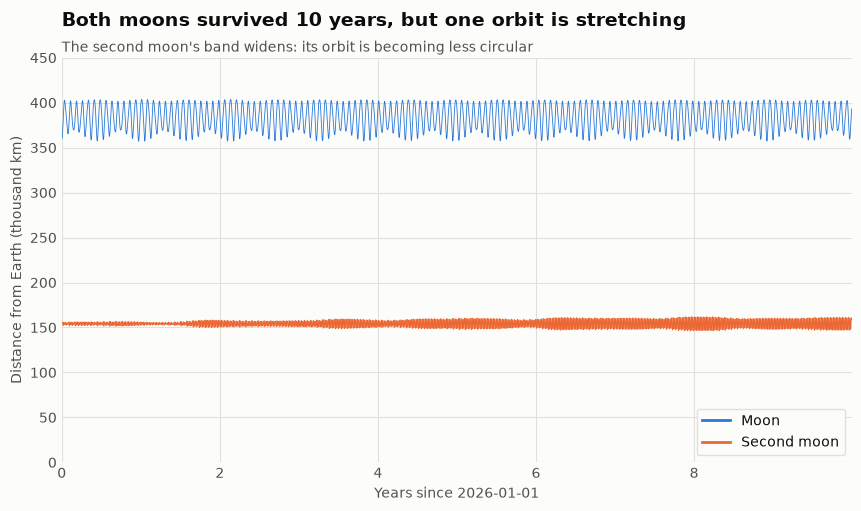

In [5]:
from plot_single_run import MOONS, plot_distances, plot_energy, yearly_range_km

plot_distances(result);
for name, label, _ in MOONS:
    for year, (closest, farthest) in yearly_range_km(result, name).items():
        print(f"{label}, {year} year: spread {farthest - closest:,.0f} km")

**Result.** The height of each band reflects orbital eccentricity, and a circular orbit would
appear as a flat line. The Moon's band is steady. The second moon starts circular, but its yearly
distance range grows from 5,847 km to 14,726 km, a factor of about 2.5: lunar perturbations are
exciting its eccentricity.

Both bodies survive the 10 years, yet the second moon's orbit is not unchanging. In the dataset
(Phase 2), `survived` is therefore defined as a lifetime of at least 100 years (right-censored),
not as long-term stability. Whether the eccentricity growth continues or oscillates requires a
longer integration.

## 5. Energy conservation

With gravity as the only force, total energy is conserved, so its computed change measures
numerical error.

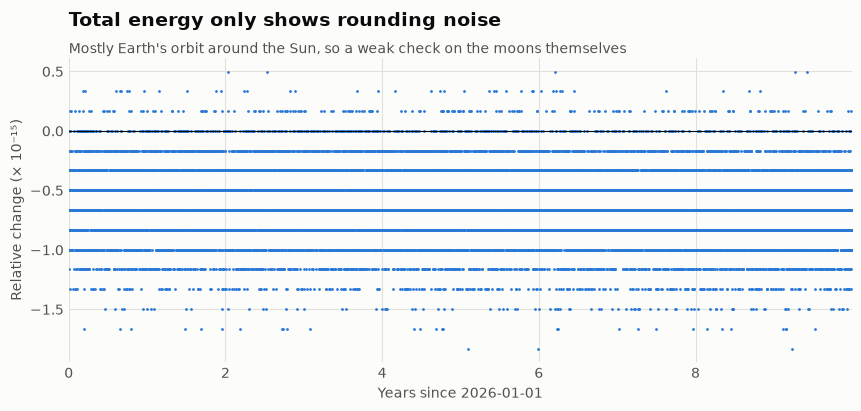

In [6]:
plot_energy(result);

**Result.** The relative energy change stays at the 10⁻¹⁵ level, on discrete levels set by
floating-point precision, with no drift. Because Earth's heliocentric orbit dominates the total
energy, this test is less sensitive to errors in the moons' orbits than the ephemeris comparison
in Section 2.

## Summary

- The simulation reproduces the Moon's position to 10.3 km over one year.
- Solar perturbations are essential, even for an Earth-centered problem.
- A low-mass second moon at 0.4 lunar distances survives 10 years with growing eccentricity:
  survival over a fixed interval does not imply an unchanging orbit.

## Questions carried into Phase 2

| Question | Outcome of Phase 2 |
|---|---|
| What time limit defines `survived`? | 100 years, the longest limit within the computing budget |
| Are outcomes sensitive to integrator tolerance? | Weakly: 6 of 100 changed, versus 12 of 100 under a 1 m displacement |
| Do outcomes depend on the start date? | No clear effect in a 30-moon test |
| Does the eccentricity growth continue? | Open |

See [`docs/questions.md`](../docs/questions.md) for all design questions and
[`docs/report.md`](../docs/report.md) for the full record.